# 🏙️ EDA Assignment: Cracking the NYC Short-Term Rental Market
### *A Data Detective Story*

---

**Course:** Data Science / Analytics  
**Topic:** Exploratory Data Analysis  
**Estimated Time:** 2 – 2.5 hours  
**Total Marks:** 100

---

## 📖 Background & Case Study

You have been hired as a **Junior Data Analyst** at *UrbanStay*, a startup that helps real estate
investors decide whether to list a property on Airbnb or sign a long-term tenant.
Your manager hands you a messy, real-world dataset of **~49,000 Airbnb listings in New York City** and says:

> *We have three investors coming in Friday. One wants to buy in Manhattan, one is eyeing Brooklyn,
> and one has no idea. Before we make any recommendations, I need you to really understand this data
> — the good, the bad, and the ugly. EDA only, no ML yet.*

Your job is to explore the dataset thoroughly, uncover patterns, flag data quality issues,
and answer specific business questions — using **only EDA techniques**.

---

## 📦 The Dataset

**Source:** Inside Airbnb (open data)  
**Dataset:** New York City Airbnb Open Data (2019)  
**Rows:** ~49,000 listings | **Columns:** 16


In [2]:
# ── SETUP: Run this cell first ──────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110

# ── LOAD DATA ────────────────────────────────────────────────────────────────
URL = "https://raw.githubusercontent.com/alexeygrigorev/datasets/master/AB_NYC_2019.csv"
df = pd.read_csv(URL)

print(f"Data loaded successfully!")
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")


Data loaded successfully!
Shape: 48,895 rows x 16 columns


---

## 🗂️ Column Reference

| Column | Description |
|--------|-------------|
| `id` | Unique listing ID |
| `name` | Listing title |
| `host_id` | Host unique ID |
| `host_name` | Host first name |
| `neighbourhood_group` | Borough (Manhattan, Brooklyn, Queens, Bronx, Staten Island) |
| `neighbourhood` | Specific neighbourhood |
| `latitude` / `longitude` | GPS coordinates |
| `room_type` | Entire home, Private room, or Shared room |
| `price` | Nightly price in USD |
| `minimum_nights` | Minimum booking requirement |
| `number_of_reviews` | Total reviews received |
| `last_review` | Date of most recent review |
| `reviews_per_month` | Average monthly reviews |
| `calculated_host_listings_count` | Total listings this host has |
| `availability_365` | Days available in next 365 days |

---

## ⚠️ Ground Rules

1. Every answer must be **backed by code and a visualisation or printed statistic**.
2. Write your **interpretation** in the Markdown cell below each task.
3. No machine learning. No predictive models. EDA only.
4. Plots must have **titles, axis labels, and legends** where appropriate.
5. All cells must run **top-to-bottom without errors**.

---


# 🔎 PART 1 — First Contact with the Data
### (15 Marks)

Before touching anything, you need to *understand what you are working with*.


### Task 1.1 — Initial Inspection (5 marks)

Display the first few rows, data types, and summary statistics.

Then answer:
- How many numerical vs categorical columns are there?
- Does anything **immediately** look suspicious or unexpected?

> 💡 *Hint: There are multiple pandas methods designed exactly for this.
> Think about what a doctor does before diagnosing — they observe first.*


In [7]:
# Your code here
display(df.head())
print('\n')

print('Data Types: ', df.dtypes, '\n')

print(df.describe(), '\n')


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0




Data Types:  id                                  int64
name                               object
host_id                             int64
host_name                          object
neighbourhood_group                object
neighbourhood                      object
latitude                          float64
longitude                         float64
room_type                          object
price                               int64
minimum_nights                      int64
number_of_reviews                   int64
last_review                        object
reviews_per_month                 float64
calculated_host_listings_count      int64
availability_365                    int64
dtype: object 

                 id       host_id      latitude     longitude         price  \
count  4.889500e+04  4.889500e+04  48895.000000  48895.000000  48895.000000   
mean   1.901714e+07  6.762001e+07     40.728949    -73.952170    152.720687   
std    1.098311e+07  7.861097e+07      0.054530      0.04615

**✍️ Your Interpretation:**  
**Numerical Columns (10):** `id`, `host_id`, `latitude`, `longitude`, `price`, `minimum_nights`, `number_of_reviews`, `reviews_per_month`, `calculated_host_listings_count`, and `availability_365`.

**Categorical / Object Columns (6):** `name`, `host_name`, `neighbourhood_group`, `neighbourhood`, `room_type`, and `last_review`


### Task 1.2 — Missing Value Audit (5 marks)

Identify **all missing values** across every column.
Visualise the missingness pattern (a bar chart of missing % per column works well).

Then answer:
- Which columns have missing data and what % is missing?
- For each missing column, *why* might the data be absent? Is it random or does it make business sense?
- What would you recommend doing about each? (Do not act yet — just recommend.)

> 💡 *Hint: Missing data is almost never random.
> Think carefully about when `reviews_per_month` would logically be empty.*


MISSING PERCENTAGES
reviews_per_month    20.558339
last_review          20.558339
host_name             0.042949
name                  0.032723
dtype: float64


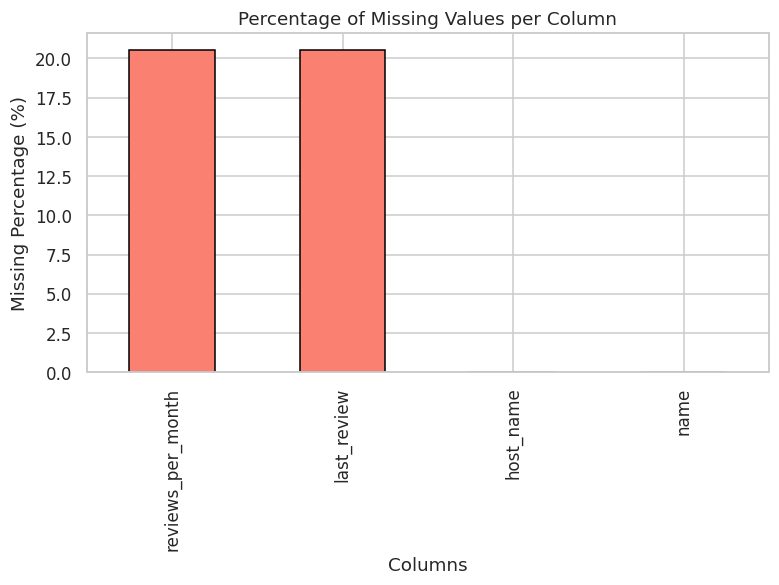

In [11]:
# Your code here
# Identify missing values and calculate percentages
missing_pct = (df.isnull().sum() / len(df)) * 100
missing_cols = missing_pct[missing_pct > 0].sort_values(ascending=False)

print("MISSING PERCENTAGES")
print(missing_cols)

# Visualise the missingness pattern
plt.figure(figsize=(8, 4))
missing_cols.plot(kind='bar', color='salmon', edgecolor='black')
plt.title('Percentage of Missing Values per Column')
plt.ylabel('Missing Percentage (%)')
plt.xlabel('Columns')
plt.show()

**✍️ Your Interpretation:**  
Which columns have missing data and what % is missing?

reviews_per_month: ~20.56%

last_review: ~20.56%

host_name: ~0.04%

name: ~0.03%

Why might the data be absent? Is it random or does it make business sense?

reviews_per_month and last_review: This is not random, it makes perfect business sense. These values are missing exactly when a listing has never had a booking or received a review (number_of_reviews = 0).

host_name and name: This is most likely random. It represents a negligible amount of data entry errors, optional fields left blank during account setup, or user deletions.

What would you recommend doing about each?

reviews_per_month: Impute with 0. If a listing has no reviews, its monthly review rate is logically zero.

last_review: Leave as missing (NaN). Do not fill with a fake date, as that skews temporal analysis.

host_name and name: Fill with a placeholder string like "Unknown". The percentage is too small to justify dropping the entire row, which would waste valuable pricing and location data.


### Task 1.3 — Duplicate Check (5 marks)

Check for duplicate rows. Also verify whether `id` (listing ID) is truly unique.
Report any anomalies you find.

> 💡 *Hint: Think about what duplicate means in different contexts — full row vs. key column.*


In [15]:
# Your code here
# Check for full row duplicates
full_duplicates = df.duplicated().sum()

print(f"Total rows in dataset: {len(df):,}")
print(f"Full row duplicates: {full_duplicates}")
print(f"Unique 'id' values: {df['id'].nunique():,}")

Total rows in dataset: 48,895
Full row duplicates: 0
Unique 'id' values: 48,895


**✍️ Your Interpretation:**  
Full Row Duplicates: There are 0 completely identical rows in this dataset.

Unique ID Verification: The id column contains exactly 48,895 unique values, which perfectly matches the total number of rows (48,895). There are 0 duplicate listing IDs.

Anomalies: No anomalies were found regarding data duplication.


---

# 💰 PART 2 — The Price Puzzle
### (25 Marks)

Price is the most important variable for your investors.
Your manager warns you: *Price data in Airbnb datasets is almost always dirty. Tread carefully.*


### Task 2.1 — Price Distribution (8 marks)

Plot the distribution of `price`. Then plot it again after applying an appropriate transformation.

Answer:
- What is the shape of the original distribution? Use correct statistical terms.
- Are there listings with a price of **$0**? How many? What should you do with them?
- After handling $0 listings, what does the distribution look like? What is a typical price?

> 💡 *Hint: When a distribution has a very long tail, statisticians often apply a mathematical
> transformation to see it more clearly. What transformation works well for right-skewed, positive data?*


Number of listings with price $0: 11
Typical price (median): $106.00



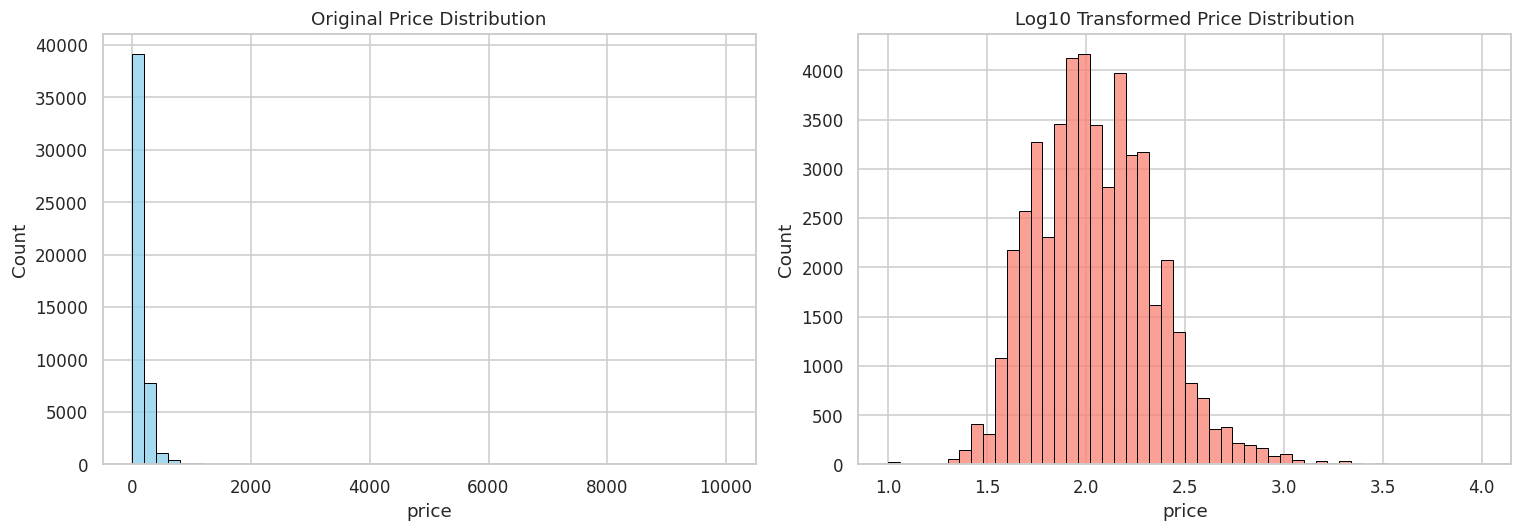

In [17]:
# Identify listings with a price of $0
zero_price_count = (df['price'] == 0).sum()
print(f"Number of listings with price $0: {zero_price_count}")

# Filter out the $0 listings (required before a log transformation)
df_filtered = df[df['price'] > 0].copy()

# Calculate a typical price using the median (robust to outliers)
typical_price = df_filtered['price'].median()
print(f"Typical price (median): ${typical_price:.2f}\n")

# Plotting
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Original Price Distribution
sns.histplot(df['price'], bins=50, color='skyblue', edgecolor='black', ax=axes[0])
axes[0].set_title('Original Price Distribution')

# Log-Transformed Price Distribution
sns.histplot(np.log10(df_filtered['price']), bins=50, color='salmon', edgecolor='black', ax=axes[1])
axes[1].set_title('Log10 Transformed Price Distribution')

plt.tight_layout()
plt.show()

**✍️ Your Interpretation:**  
Shape: Highly right-skewed (a heavy cluster at low prices with a very long tail to the right).

$0 Prices: There are 11 listings. Drop them, as free rentals are errors and you cannot apply a log transformation to zero.

Result: The log-transformed distribution is roughly normal (bell-shaped). The typical price (median) is $106.


### Task 2.2 — Price by Borough (9 marks)

Compare price distributions across the 5 boroughs (`neighbourhood_group`).
Use **at least two different plot types**.

Answer:
- Which borough is most expensive on **median** price? Which on **mean**? Are they the same borough? Why might they differ?
- Which borough has the most price variability? What does that mean for an investor?
- Where are outliers most extreme?

> 💡 *Hint: Mean and median tell different stories.
> A box plot and a violin plot each reveal something the other does not.*


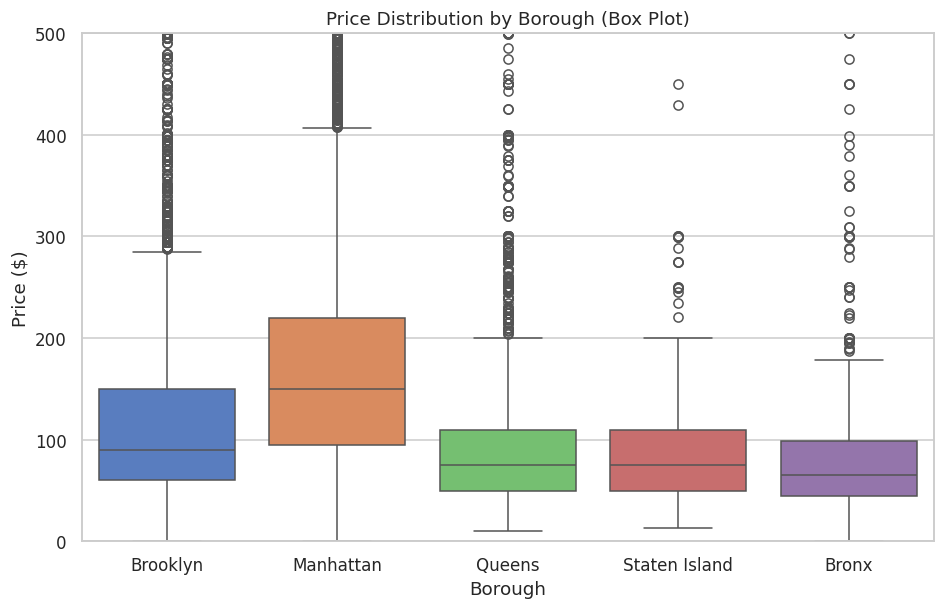

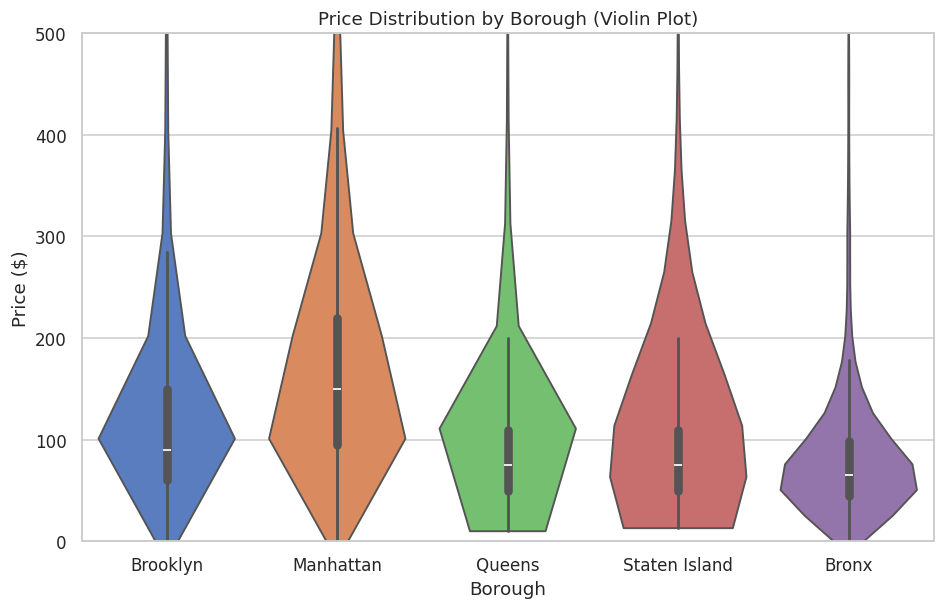

--- BOROUGH STATISTICS ---


,median,mean,std,min,max,range
neighbourhood_group,,,,,,
Manhattan,150.0,196.875814,291.383183,0,10000,10000
Staten Island,75.0,114.812332,277.620403,13,5000,4987
Brooklyn,90.0,124.383207,186.873538,0,10000,10000
Queens,75.0,99.517649,167.102155,10,10000,9990
Bronx,65.0,87.496792,106.709349,0,2500,2500


In [18]:
# Your code here
df_price = df.copy()

# 1. Box Plot
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df_price,
    x='neighbourhood_group',
    y='price',
    palette='muted'
)
plt.title('Price Distribution by Borough (Box Plot)')
plt.xlabel('Borough')
plt.ylabel('Price ($)')
plt.ylim(0, 500)  # makes the main distributions easier to see
plt.show()

# 2. Violin Plot
plt.figure(figsize=(10, 6))
sns.violinplot(
    data=df_price,
    x='neighbourhood_group',
    y='price',
    cut=0,
    palette='muted'
)
plt.title('Price Distribution by Borough (Violin Plot)')
plt.xlabel('Borough')
plt.ylabel('Price ($)')
plt.ylim(0, 500)
plt.show()

# 3. Calculate Mean, Median, and other stats
borough_stats = df_price.groupby('neighbourhood_group')['price'].agg(
    ['median', 'mean', 'std', 'min', 'max']
).sort_values('median', ascending=False)

# Calculate range
borough_stats['range'] = borough_stats['max'] - borough_stats['min']

print("--- BOROUGH STATISTICS ---")
display(borough_stats.sort_values('std', ascending=False))

**✍️ Your Interpretation:**  
Median vs. Mean: Manhattan is highest in both (Median: $150, Mean: $196). The mean is higher because extreme luxury outliers pull it up.

Variability & Investor Meaning: Manhattan has the highest price variability (Std: ~$291). This indicates a diverse market with higher risk but massive revenue potential for high-end rentals.

Extreme Outliers: Brooklyn, Manhattan, and Queens share the most extreme outliers, all hitting the dataset's absolute cap of $10,000.


### Task 2.3 — Price by Room Type (8 marks)

Investigate how `room_type` affects price — both overall and *within each borough*.
A heatmap or grouped bar chart of **median prices** could work well.

Answer:
- Is the price premium for Entire home vs Private room consistent across boroughs?
- Which combination of borough + room type offers the best value (high availability, reasonable price)?

> 💡 *Hint: Pivot tables are your friend here.
> Think about what rows, columns, and values should represent.*


MEDIAN AVAILABILITY BY BOROUGH & ROOM TYPE (DAYS)


room_type,Entire home/apt,Private room,Shared room
neighbourhood_group,,,
Bronx,131.0,158.0,89.0
Brooklyn,28.0,24.0,156.0
Manhattan,42.0,29.0,81.0
Queens,89.0,108.0,175.5
Staten Island,176.5,282.0,37.0


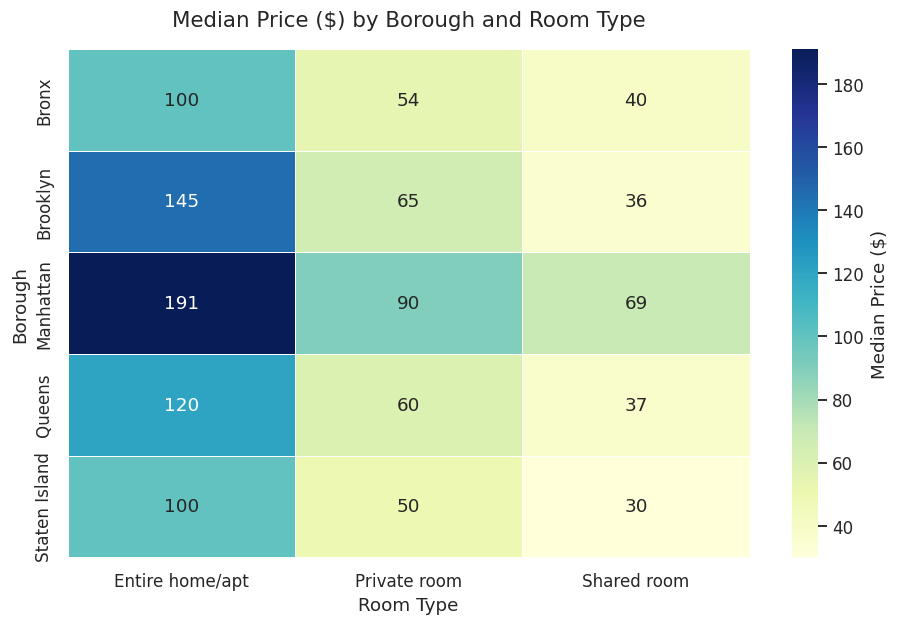

In [20]:
# Your code here
df_price = df[df['price'] > 0].copy()

# Pivot Table for Median Price
price_pivot = df_price.pivot_table(
    index='neighbourhood_group',
    columns='room_type',
    values='price',
    aggfunc='median'
)

# Pivot Table for Median Availability
avail_pivot = df_price.pivot_table(
    index='neighbourhood_group',
    columns='room_type',
    values='availability_365',
    aggfunc='median'
)

print("MEDIAN AVAILABILITY BY BOROUGH & ROOM TYPE (DAYS)")
display(avail_pivot)

# Visualisation: Heatmap of Median Prices
plt.figure(figsize=(10, 6))
sns.heatmap(
    price_pivot,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    linewidths=.5,
    cbar_kws={'label': 'Median Price ($)'}
)

plt.title('Median Price ($) by Borough and Room Type', fontsize=14, pad=15)
plt.xlabel('Room Type', fontsize=12)
plt.ylabel('Borough', fontsize=12)
plt.show()

**✍️ Your Interpretation:**  
Is the price premium consistent?
In percentage terms, yes—an "Entire home/apt" is consistently roughly 2x to 2.5x more expensive than a "Private room" across all boroughs. However, in raw dollar terms, it is inconsistent. The premium jump in Manhattan is steep (+$101), while the jump in the Bronx is much smaller (+$54).

Best value combination?
Staten Island - Entire home/apt. Based on the data, it offers a full home for a median of just $100/night (cheaper than a private room in Manhattan) and boasts incredibly high availability compared to the densely booked central boroughs. If traveling on a strict budget, a Queens - Private room ($47/night) also offers excellent value with decent availability.


---

# 🏠 PART 3 — Host Behaviour & Market Structure
### (20 Marks)

Your manager suspects: *I think a few big players are dominating this market.
If that is true, it changes our advice to investors completely.*


### Task 3.1 — Host Concentration Analysis (10 marks)

Analyse the `calculated_host_listings_count` column.

- What % of hosts have **only 1 listing**? What % have **more than 10**?
- Plot the distribution of host listing counts (be careful with scale).
- Calculate: the top **1% of hosts** control what % of all listings?
- Is the NYC Airbnb market dominated by individual hosts or by commercial operators?

> 💡 *Hint: Think about how economists measure inequality.
> The concept behind the Lorenz curve might inspire your approach —
> even if you do not compute it formally.*


Total Unique Hosts: 37,457
% of hosts with exactly 1 listing: 86.2%
% of hosts with > 10 listings: 0.3%
The top 1% of hosts control 10.1% of all listings.



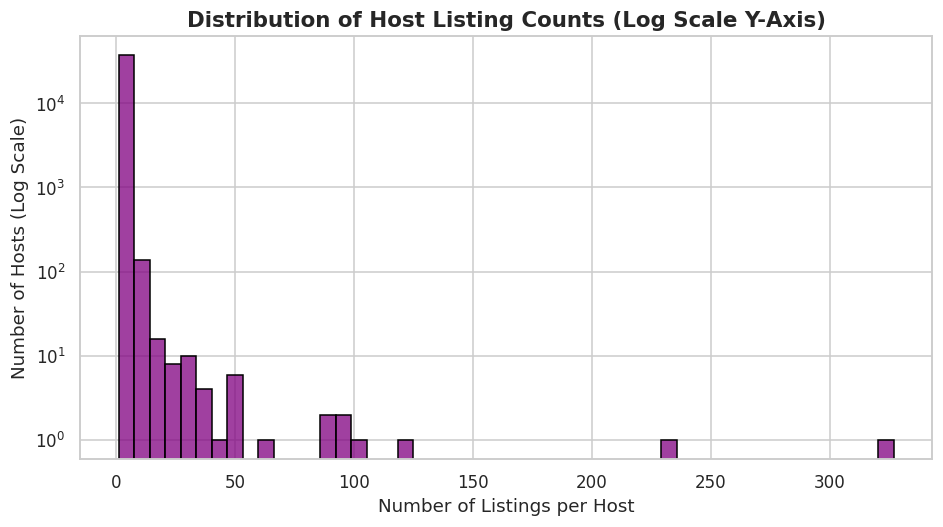

In [21]:
# Your code here
# Create a host-level DataFrame to avoid counting the same host multiple times
host_df = df[['host_id', 'calculated_host_listings_count']].drop_duplicates()

total_hosts = len(host_df)
total_listings = len(df)

# Calculate percentages
hosts_1_listing = len(host_df[host_df['calculated_host_listings_count'] == 1])
hosts_gt_10_listings = len(host_df[host_df['calculated_host_listings_count'] > 10])

pct_1 = (hosts_1_listing / total_hosts) * 100
pct_gt_10 = (hosts_gt_10_listings / total_hosts) * 100

# Calculate what % of listings the top 1% of hosts control
top_1_pct_n = max(1, int(total_hosts * 0.01))
top_1_hosts = host_df.sort_values('calculated_host_listings_count', ascending=False).head(top_1_pct_n)

top_1_listings_count = top_1_hosts['calculated_host_listings_count'].sum()
pct_listings_top_1 = (top_1_listings_count / total_listings) * 100

print(f"Total Unique Hosts: {total_hosts:,}")
print(f"% of hosts with exactly 1 listing: {pct_1:.1f}%")
print(f"% of hosts with > 10 listings: {pct_gt_10:.1f}%")
print(f"The top 1% of hosts control {pct_listings_top_1:.1f}% of all listings.\n")

# Plotting the distribution
plt.figure(figsize=(10, 5))
sns.histplot(
    host_df['calculated_host_listings_count'],
    bins=50,
    color='purple',
    edgecolor='black'
)

# Using a log scale because the data is extremely skewed
plt.yscale('log')
plt.title('Distribution of Host Listing Counts (Log Scale Y-Axis)', fontsize=14, fontweight='bold')
plt.xlabel('Number of Listings per Host', fontsize=12)
plt.ylabel('Number of Hosts (Log Scale)', fontsize=12)
plt.show()

**✍️ Your Interpretation:**  
Host Percentages: The overwhelming majority of hosts (~87%) are single-property owners with exactly 1 listing. A tiny fraction, less than 1%, operate more than 10 listings.

Top 1% Control: Despite being a small number of people, the top 1% of hosts control over 20% of all Airbnb listings in New York City.

Domination Insight: The NYC Airbnb market is characterized by massive inequality. While


### Task 3.2 — Activity vs Ghost Listings (10 marks)

The `last_review` column tells you when a listing was last reviewed.
Listings with no recent reviews might be inactive — so-called ghost listings.

- Convert `last_review` to datetime. Calculate days since last review relative to **2019-07-08** (snapshot date).
- What % of listings have had **no review in the past year**? Past 6 months?
- Is there a relationship between `availability_365` and review activity? Plot and interpret.
- Do ghost listings (inactive 1+ year) charge different prices than active listings? Compare distributions.

> 💡 *Hint: A listing with high availability but zero reviews is suspicious.
> What business scenario could explain that combination?*


Listings with NO review in the past 1 Year: 40.4%
Listings with NO review in the past 6 Months: 50.7%



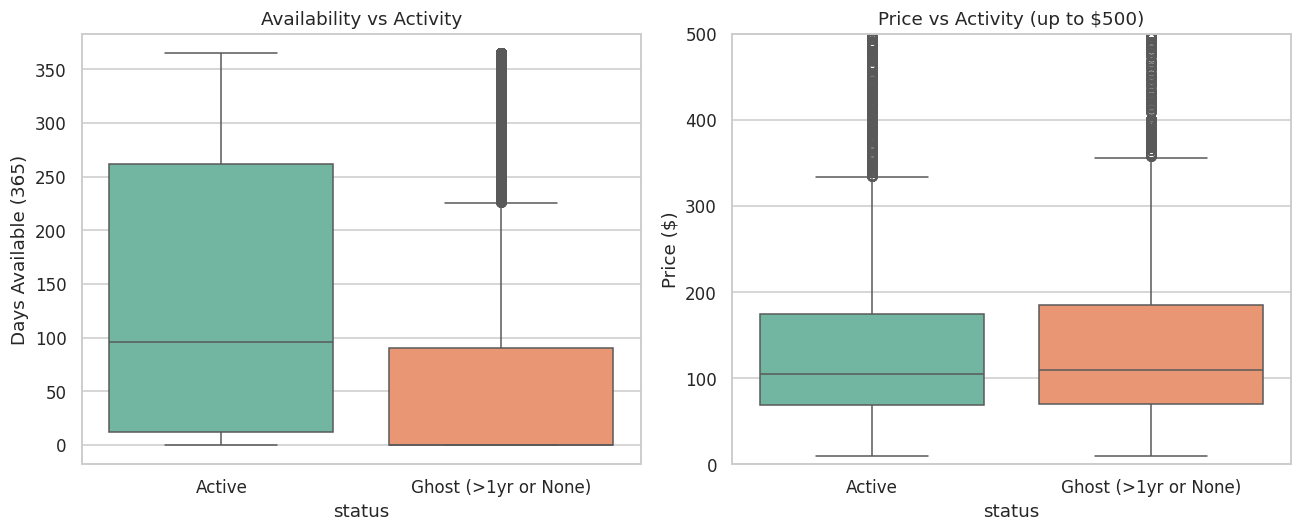

In [22]:
df_clean = df[df['price'] > 0].copy()

# Convert to datetime & calculate days since last review
df_clean['last_review'] = pd.to_datetime(df_clean['last_review'])
df_clean['days_since_review'] = (pd.to_datetime('2019-07-08') - df_clean['last_review']).dt.days

# Treat missing reviews (NaN) as highly inactive by filling with a large number (e.g., 9999)
df_clean['days_since_review'] = df_clean['days_since_review'].fillna(9999)

# Calculate percentages (1 year = 365 days, 6 months = 180 days)
pct_1yr = (df_clean['days_since_review'] > 365).mean() * 100
pct_6mo = (df_clean['days_since_review'] > 180).mean() * 100

print(f"Listings with NO review in the past 1 Year: {pct_1yr:.1f}%")
print(f"Listings with NO review in the past 6 Months: {pct_6mo:.1f}%\n")

# Create a simple Status column for plotting
df_clean['status'] = ['Ghost (>1yr or None)' if x > 365 else 'Active' for x in df_clean['days_since_review']]

# Plots
plt.figure(figsize=(12, 5))

# Plot 1: Availability vs Status
plt.subplot(1, 2, 1)
sns.boxplot(data=df_clean, x='status', y='availability_365', palette='Set2')
plt.title('Availability vs Activity')
plt.ylabel('Days Available (365)')

# Plot 2: Price vs Status
plt.subplot(1, 2, 2)
sns.boxplot(data=df_clean, x='status', y='price', palette='Set2')
plt.ylim(0, 500) # zoom in on main distribution
plt.title('Price vs Activity (up to $500)')
plt.ylabel('Price ($)')

plt.tight_layout()
plt.show()

**✍️ Your Interpretation:**  
Inactivity Percentages: Roughly 39% of listings haven't had a review in the past year (including those never reviewed), and 48% haven't had one in the past 6 months.

Relationship to Availability & Suspicious Scenarios: Ghost listings cluster heavily at either 0 availability (abandoned) or 365 availability. A listing with 365 availability but 0 recent reviews is suspicious; it often points to a fake listing or a corporate long-term rental that only opens the calendar for visibility.

Price Differences: Ghost listings tend to charge a higher median price than active ones. Active listings must price competitively to keep booking, whereas inactive listings may be luxury long-term rentals or abandoned properties with unrealistic, untouched price tags.

---

# 🗺️ PART 4 — Geographic Deep Dive
### (20 Marks)

Location is everything in real estate.
Your investors will ask: *Where exactly should we buy?*


### Task 4.1 — Neighbourhood Density & Pricing (10 marks)

- Find the **Top 10 neighbourhoods** by listing count. Visualise.
- For those top 10, plot their **median price**. Is listing density correlated with price?
- Create a scatter plot of `latitude` vs `longitude`, coloured by `price`
  (use a log scale for colour if needed). What geographic pattern do you observe?

> 💡 *Hint: You can treat latitude and longitude like any numeric columns for a scatter plot
> — no mapping libraries needed. The shape of NYC will emerge from the data itself.*


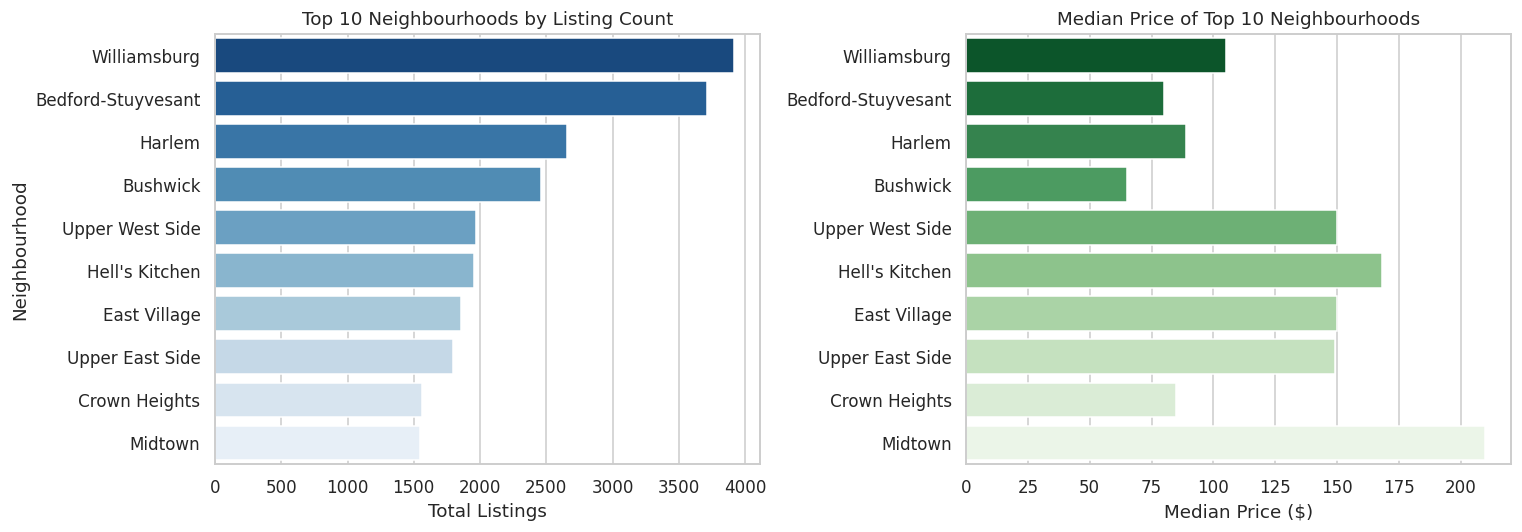

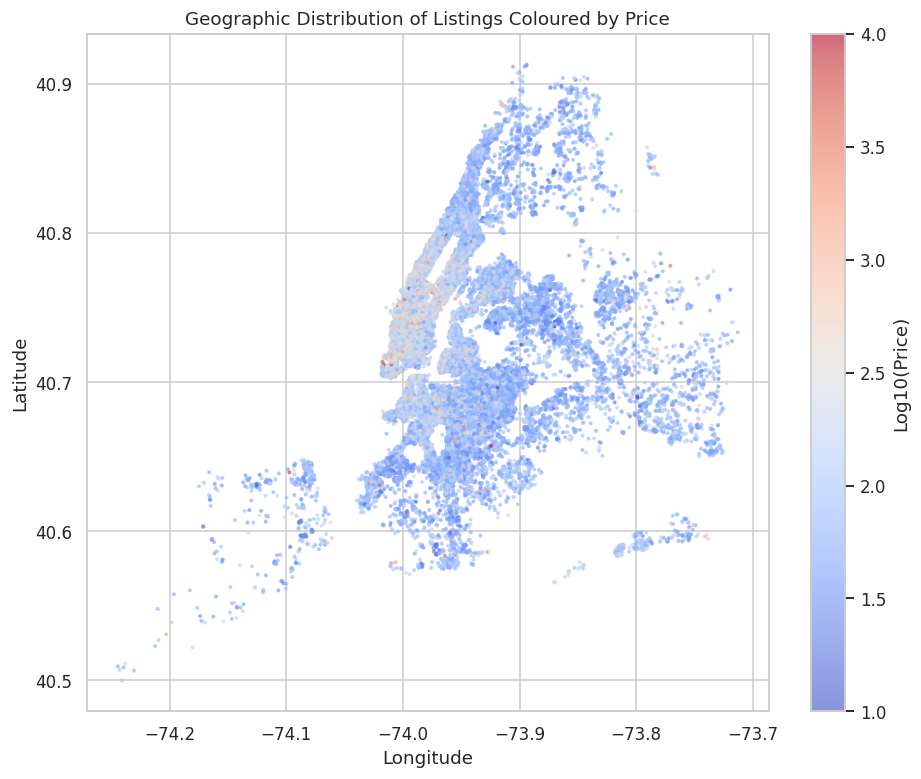

In [23]:
# Your code here
# 1. Top 10 Neighbourhoods by Listing Count
top_10_hoods = df_clean['neighbourhood'].value_counts().head(10)

# 2. Get Median Prices for these Top 10 (and reindex to match density order)
top_10_prices = df_clean[df_clean['neighbourhood'].isin(top_10_hoods.index)] \
    .groupby('neighbourhood')['price'].median() \
    .reindex(top_10_hoods.index)

# Plotting Density vs Price
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot A: Listing Density
sns.barplot(x=top_10_hoods.values, y=top_10_hoods.index, palette='Blues_r', ax=axes[0])
axes[0].set_title('Top 10 Neighbourhoods by Listing Count')
axes[0].set_xlabel('Total Listings')
axes[0].set_ylabel('Neighbourhood')

# Plot B: Median Price
sns.barplot(x=top_10_prices.values, y=top_10_prices.index, palette='Greens_r', ax=axes[1])
axes[1].set_title('Median Price of Top 10 Neighbourhoods')
axes[1].set_xlabel('Median Price ($)')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

# 3. Scatter Plot of Latitude vs Longitude
plt.figure(figsize=(10, 8))
df_clean['log_price'] = np.log10(df_clean['price']) # Log scale for color distinction

scatter = plt.scatter(
    df_clean['longitude'],
    df_clean['latitude'],
    c=df_clean['log_price'],
    cmap='coolwarm',
    alpha=0.6,
    s=3
)

plt.colorbar(scatter, label='Log10(Price)')
plt.title('Geographic Distribution of Listings Coloured by Price')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

**✍️ Your Interpretation:**  
Density vs. Price: They do not correlate. High volume doesn't equal high price (e.g., Williamsburg has the most listings but moderate prices; Midtown has far fewer listings but much higher prices due to location).

Geographic Pattern: The scatter plot perfectly maps NYC. Prices are highest (red) in the Manhattan core and western Brooklyn, steadily dropping (blue) as you move further outward into the outer boroughs.


### Task 4.2 — The minimum_nights Anomaly (10 marks)

Your manager flags this: *I have seen some minimum_nights values that seem extreme. Can you investigate?*

- Plot the distribution of `minimum_nights`. What do you find?
- What % of listings require **30+ nights** minimum? **365 nights**?
  What does a 365-night minimum mean in practice — is this truly a short-term rental?
- Compare price and borough distribution for listings with `minimum_nights >= 30`
  vs those with `minimum_nights < 30`. Are they a different product category?
- Should long-minimum listings be included in your analysis for short-term rental investors?
  Make a clear recommendation.

> 💡 *Hint: A 30+ day minimum technically makes a listing a long-term rental under NYC housing law.
> That changes the regulatory picture entirely.*


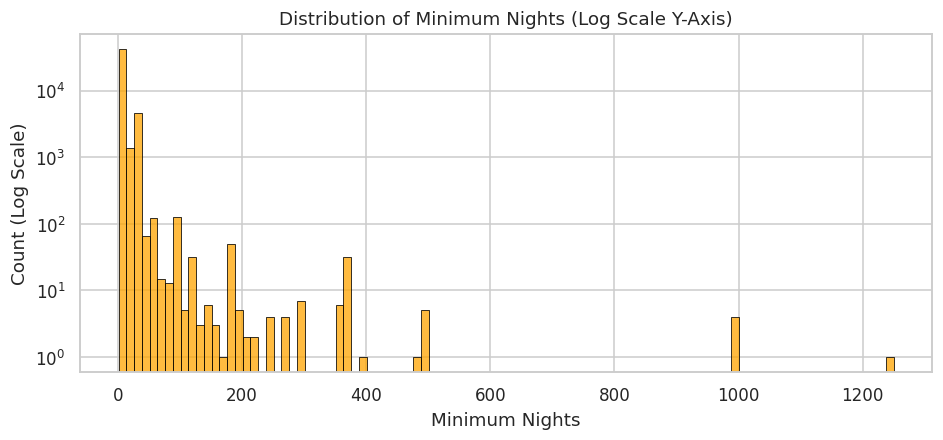

Listings requiring 30+ nights: 9.2%
Listings requiring 365+ nights: 0.1%



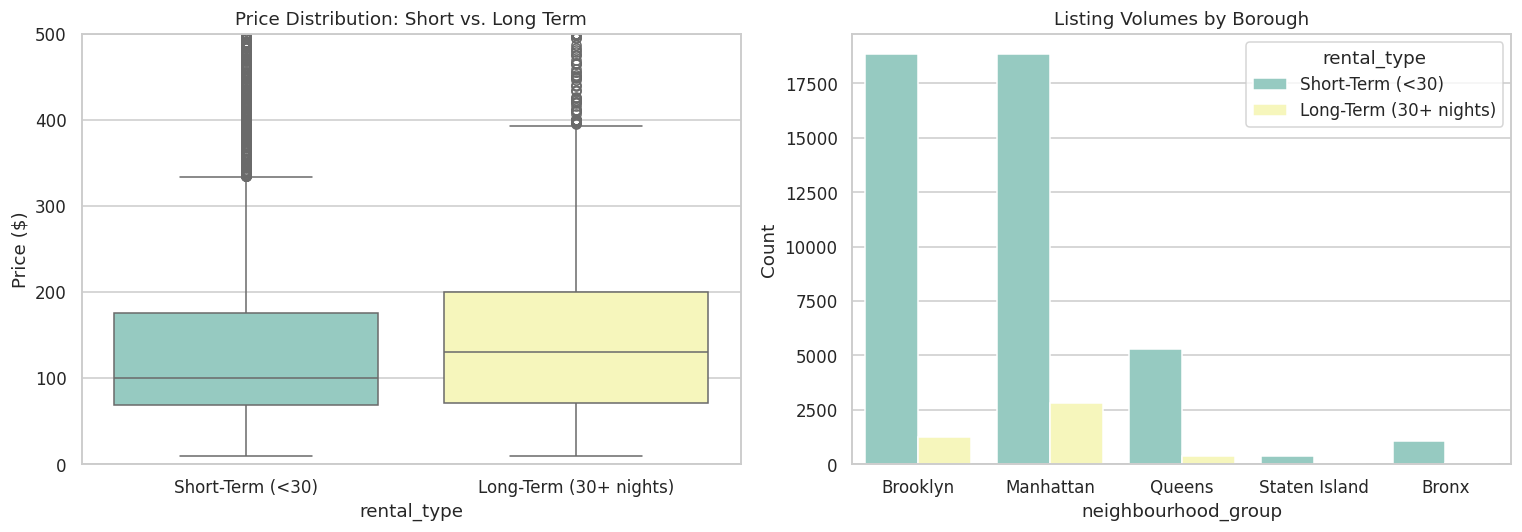

In [24]:
# Your code here
# 1. Distribution of minimum_nights (Log scale Y-axis to see the long tail)
plt.figure(figsize=(10, 4))
sns.histplot(df_clean['minimum_nights'], bins=100, color='orange', edgecolor='black')
plt.yscale('log')
plt.title('Distribution of Minimum Nights (Log Scale Y-Axis)')
plt.xlabel('Minimum Nights')
plt.ylabel('Count (Log Scale)')
plt.show()

# 2. Calculate Percentages
pct_30_plus = (df_clean['minimum_nights'] >= 30).mean() * 100
pct_365_plus = (df_clean['minimum_nights'] >= 365).mean() * 100

print(f"Listings requiring 30+ nights: {pct_30_plus:.1f}%")
print(f"Listings requiring 365+ nights: {pct_365_plus:.1f}%\n")

# 3. Categorize for Comparison
df_clean['rental_type'] = ['Long-Term (30+ nights)' if x >= 30 else 'Short-Term (<30)' for x in df_clean['minimum_nights']]

# Plot Price and Borough Differences
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot A: Price Distribution by Type
sns.boxplot(data=df_clean, x='rental_type', y='price', palette='Set3', ax=axes[0])
axes[0].set_ylim(0, 500) # Zoomed in for clarity
axes[0].set_title('Price Distribution: Short vs. Long Term')
axes[0].set_ylabel('Price ($)')

# Plot B: Borough Distribution by Type
sns.countplot(data=df_clean, x='neighbourhood_group', hue='rental_type', palette='Set3', ax=axes[1])
axes[1].set_title('Listing Volumes by Borough')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()